In [1]:
import numpy as np
import basilisk_runner
import importlib
import dynamics
import utils
import matplotlib.pyplot as plt

/Users/shash/Documents/Projects/SatelliteRendezvous/venv/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
importlib.reload(basilisk_runner)
importlib.reload(dynamics)
importlib.reload(utils)

<module 'utils' from '/Users/shash/Documents/Projects/SatelliteRendezvous/utils.py'>

In [3]:
from basilisk_runner import run_orbit
from Basilisk.utilities import orbitalMotion, simIncludeGravBody
from Basilisk.architecture import messaging

In [ ]:
import numpy as np

from Basilisk.architecture import messaging, sysModel
from Basilisk.simulation import (
    reactionWheelStateEffector,
    spacecraft,
    thrusterDynamicEffector,
)
from Basilisk.utilities import (
    SimulationBaseClass,
    macros,
    simIncludeRW,
    simIncludeThruster,
)

dt_s = 0.005
burn_s = 2.0
duration_s = 15.0
motor_limit_nm = 0.05
jet_thrust_n = 0.05
arm_m = 0.4

dump_torque_nm = -2 * arm_m * jet_thrust_n
burn_ns = macros.sec2nano(burn_s)


class DumpPointingController(sysModel.SysModel):
    def __init__(self, state_msg):
        super().__init__()
        self.ModelTag = "DumpPointingController"
        self.state_msg = state_msg
        self.motor_cmd = messaging.ArrayMotorTorqueMsg()

    def UpdateState(self, current_time_ns):
        state = self.state_msg.read()
        sigma = np.asarray(state.sigma_BN).reshape(3)
        omega = np.asarray(state.omega_BN_B).reshape(3)

        pointing_torque = -0.8 * sigma - 4.0 * omega

        expected_rcs_torque = np.zeros(3)
        if current_time_ns < burn_ns:
            expected_rcs_torque[2] = dump_torque_nm

        motor_torque = np.clip(
            expected_rcs_torque - pointing_torque,
            -motor_limit_nm,
            motor_limit_nm,
        )

        payload = messaging.ArrayMotorTorqueMsgPayload()
        commands = list(payload.motorTorque)
        commands[:3] = motor_torque.tolist()
        payload.motorTorque = commands
        self.motor_cmd.write(payload, current_time_ns, self.moduleID)


sim = SimulationBaseClass.SimBaseClass()
task_name = "momentumDump"
process = sim.CreateNewProcess("dynamics")
process.addTask(sim.CreateNewTask(task_name, macros.sec2nano(dt_s)))

chaser = spacecraft.Spacecraft()
chaser.ModelTag = "Chaser"
chaser.hub.mHub = 150.0
chaser.hub.IHubPntBc_B = np.diag([20.0, 25.0, 15.0]).tolist()

wheel_factory = simIncludeRW.rwFactory()
wheels = reactionWheelStateEffector.ReactionWheelStateEffector()

for axis, initial_rpm in zip(np.eye(3), (0.0, 0.0, 30.0)):
    wheel = wheel_factory.create(
        "Honeywell_HR16",
        axis.tolist(),
        RWModel=messaging.BalancedWheels,
        Omega=initial_rpm,
        Omega_max=6000.0,
        maxMomentum=50.0,
        u_max=motor_limit_nm,
    )

z_wheel_inertia = wheel.Js 
wheel_factory.addToSpacecraft("ChaserWheels", wheels, chaser)

rcs = thrusterDynamicEffector.ThrusterDynamicEffector()
thruster_factory = simIncludeThruster.thrusterFactory()

for position, direction in (
    ([arm_m, 0.0, 0.0], [0.0, -1.0, 0.0]),
    ([-arm_m, 0.0, 0.0], [0.0, 1.0, 0.0]),
):
    thruster_factory.create(
        "Blank_Thruster",
        position,
        direction,
        MaxThrust=jet_thrust_n,
        steadyIsp=60.0,
    )

thruster_factory.addToSpacecraft("DumpJets", rcs, chaser)

rcs_cmd = messaging.THRArrayOnTimeCmdMsg()
rcs.cmdsInMsg.subscribeTo(rcs_cmd)

pulse = messaging.THRArrayOnTimeCmdMsgPayload()
on_times = list(pulse.OnTimeRequest)
on_times[:2] = [burn_s, burn_s]
pulse.OnTimeRequest = on_times

controller = DumpPointingController(chaser.scStateOutMsg)
wheels.rwMotorCmdInMsg.subscribeTo(controller.motor_cmd)

state_rec = chaser.scStateOutMsg.recorder()
wheel_rec = wheels.rwSpeedOutMsg.recorder()
motor_rec = controller.motor_cmd.recorder()
jet_recs = [msg.recorder() for msg in rcs.thrusterOutMsgs]

sim.AddModelToTask(task_name, controller, ModelPriority=30)
sim.AddModelToTask(task_name, rcs, ModelPriority=20)
sim.AddModelToTask(task_name, wheels, ModelPriority=20)
sim.AddModelToTask(task_name, chaser, ModelPriority=10)

for recorder in (state_rec, wheel_rec, motor_rec, *jet_recs):
    sim.AddModelToTask(task_name, recorder, ModelPriority=0)

sim.InitializeSimulation()
rcs_cmd.write(pulse)
sim.ConfigureStopTime(macros.sec2nano(duration_s))
sim.ExecuteSimulation()

t = state_rec.times() * macros.NANO2SEC
z_momentum = z_wheel_inertia * np.asarray(wheel_rec.wheelSpeeds)[:, 2]
z_motor_torque = np.asarray(motor_rec.motorTorque)[:, 2]

sigma_norm = np.linalg.norm(np.asarray(state_rec.sigma_BN), axis=1)
pointing_error_deg = np.degrees(4 * np.arctan(sigma_norm))

rcs_force = np.sum([rec.thrustForce_B for rec in jet_recs], axis=0)
rcs_torque = np.sum([rec.thrustTorquePntB_B for rec in jet_recs], axis=0)

print(f"Z wheel momentum {z_momentum[0]:.4f} → {z_momentum[-1]:.4f} N·m·s")
print(f"Peak pointing error {pointing_error_deg.max():.6f} deg")
print("Net RCS force impulse [N·s]", np.trapezoid(rcs_force, t, axis=0))

Z wheel momentum 0.2500 → 0.1699 N·m·s
Peak pointing error 0.002576 deg
Net RCS force impulse [N·s] [0. 0. 0.]


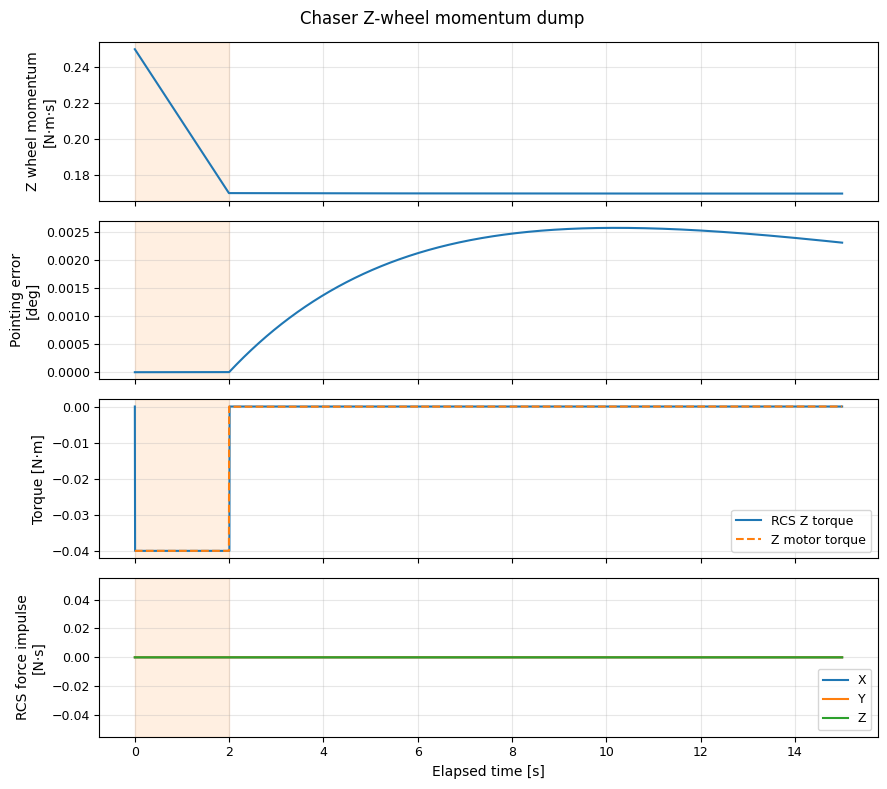

In [5]:
import matplotlib.pyplot as plt

force_impulse = np.vstack((
    np.zeros((1, 3)),
    np.cumsum(
        0.5 * (rcs_force[:-1] + rcs_force[1:]) * np.diff(t)[:, None],
        axis=0,
    ),
))

fig, axes = plt.subplots(4, 1, figsize=(9, 8), sharex=True)

axes[0].plot(t, z_momentum)
axes[0].set_ylabel("Z wheel momentum\n[N·m·s]")

axes[1].plot(t, pointing_error_deg)
axes[1].set_ylabel("Pointing error\n[deg]")

axes[2].plot(t, rcs_torque[:, 2], label="RCS Z torque")
axes[2].plot(t, z_motor_torque, "--", label="Z motor torque")
axes[2].set_ylabel("Torque [N·m]")
axes[2].legend()

for i, axis in enumerate("XYZ"):
    axes[3].plot(t, force_impulse[:, i], label=axis)

axes[3].set_ylabel("RCS force impulse\n[N·s]")
axes[3].set_xlabel("Elapsed time [s]")
axes[3].legend()

for ax in axes:
    ax.axvspan(0, burn_s, color="tab:orange", alpha=0.12)
    ax.grid(alpha=0.3)

fig.suptitle("Chaser Z-wheel momentum dump")
fig.tight_layout()
plt.show()

In [6]:
H_START = 0.22       # N·m·s
H_STOP = 0.17        # N·m·s
BURST_S = 0.10       # Recheck momentum after each burst


class AutomaticZDump(sysModel.SysModel):
    """Unload positive Z-wheel momentum while holding inertial attitude."""

    def __init__(self, state_msg, wheel_speed_msg, rcs_cmd, wheel_inertia):
        super().__init__()
        self.ModelTag = "AutomaticZDump"
        self.state_msg = state_msg
        self.wheel_speed_msg = wheel_speed_msg
        self.rcs_cmd = rcs_cmd
        self.wheel_inertia = wheel_inertia
        self.motor_cmd = messaging.ArrayMotorTorqueMsg()

        self.dumping = False
        self.burst_end_ns = 0
        self.burst_steps = round(BURST_S / dt_s)
        self.step_ns = macros.sec2nano(dt_s)

    def UpdateState(self, current_time_ns):
        state = self.state_msg.read()
        sigma = np.asarray(state.sigma_BN).reshape(3)
        omega = np.asarray(state.omega_BN_B).reshape(3)
        pointing_torque = -0.8 * sigma - 4.0 * omega

        # Reevaluate the measured momentum at the end of each burst.
        if current_time_ns >= self.burst_end_ns:
            wheel_speed = self.wheel_speed_msg.read().wheelSpeeds[2]
            h_z = self.wheel_inertia * wheel_speed

            if self.dumping and h_z <= H_STOP:
                self.dumping = False
            elif not self.dumping and h_z >= H_START:
                self.dumping = True

            if self.dumping:
                # Shorten the final burst as we approach the stop target.
                momentum_per_step = abs(dump_torque_nm) * dt_s
                steps_to_target = int(np.ceil((h_z - H_STOP) / momentum_per_step))
                steps = min(self.burst_steps, max(1, steps_to_target))
                on_time_s = steps * dt_s

                pulse = messaging.THRArrayOnTimeCmdMsgPayload()
                on_times = list(pulse.OnTimeRequest)
                on_times[:2] = [on_time_s, on_time_s]
                pulse.OnTimeRequest = on_times
                self.rcs_cmd.write(pulse, current_time_ns, self.moduleID)
                self.burst_end_ns = current_time_ns + steps * self.step_ns

        expected_rcs_torque = np.zeros(3)
        if current_time_ns < self.burst_end_ns:
            expected_rcs_torque[2] = dump_torque_nm

        motor_torque = np.clip(
            expected_rcs_torque - pointing_torque,
            -motor_limit_nm,
            motor_limit_nm,
        )

        payload = messaging.ArrayMotorTorqueMsgPayload()
        commands = list(payload.motorTorque)
        commands[:3] = motor_torque.tolist()
        payload.motorTorque = commands
        self.motor_cmd.write(payload, current_time_ns, self.moduleID)

In [7]:
controller = AutomaticZDump(
    chaser.scStateOutMsg,
    wheels.rwSpeedOutMsg,
    rcs_cmd,
    z_wheel_inertia,
)
wheels.rwMotorCmdInMsg.subscribeTo(controller.motor_cmd)

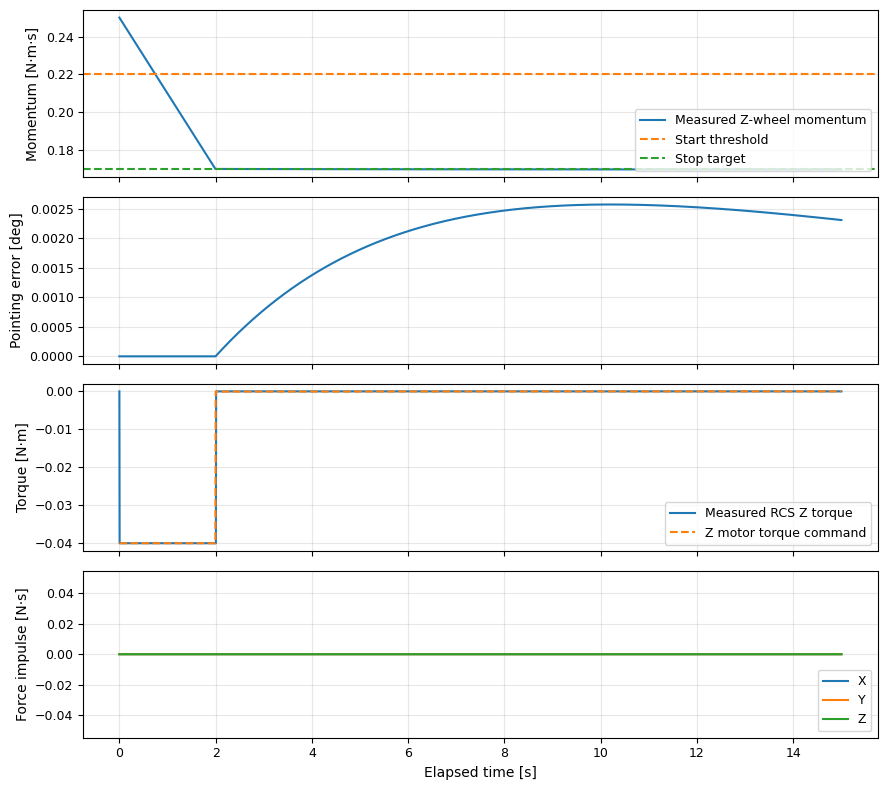

Final Z-wheel momentum 0.169943 N·m·s
Peak pointing error 0.002576 deg
Final RCS force impulse [N·s] [0. 0. 0.]


In [8]:
import matplotlib.pyplot as plt

force_impulse = np.vstack((
    np.zeros((1, 3)),
    np.cumsum(
        0.5 * (rcs_force[:-1] + rcs_force[1:]) * np.diff(t)[:, None],
        axis=0,
    ),
))

fig, axes = plt.subplots(4, 1, figsize=(9, 8), sharex=True)

axes[0].plot(t, z_momentum, label="Measured Z-wheel momentum")
axes[0].axhline(H_START, color="tab:orange", ls="--", label="Start threshold")
axes[0].axhline(H_STOP, color="tab:green", ls="--", label="Stop target")
axes[0].set_ylabel("Momentum [N·m·s]")
axes[0].legend()

axes[1].plot(t, pointing_error_deg)
axes[1].set_ylabel("Pointing error [deg]")

axes[2].plot(t, rcs_torque[:, 2], label="Measured RCS Z torque")
axes[2].plot(t, z_motor_torque, "--", label="Z motor torque command")
axes[2].set_ylabel("Torque [N·m]")
axes[2].legend()

for i, axis in enumerate("XYZ"):
    axes[3].plot(t, force_impulse[:, i], label=axis)
axes[3].set_ylabel("Force impulse [N·s]")
axes[3].set_xlabel("Elapsed time [s]")
axes[3].legend()

for ax in axes:
    ax.grid(alpha=0.3)

fig.tight_layout()
plt.show()

print(f"Final Z-wheel momentum {z_momentum[-1]:.6f} N·m·s")
print(f"Peak pointing error {pointing_error_deg.max():.6f} deg")
print("Final RCS force impulse [N·s]", force_impulse[-1])